# PROYECTO: ACA N° 2 - APRENDIZAJE AUTOMÁTICO
## Predicción de Deserción Escolar con Redes Neuronales
* **Institución:** Corporación Unificada Nacional de Educación Superior (CUN)
* **Pilar Seleccionado:** Proyecto 2: Educación (Prevención de la Deserción)
* **Dataset:** UCI Predict Students Dropout and Academic Success
* **Docente:** Dr. Hamilton Rivera Flor
* **Estudiantes:** Laura Carolina Quintero Torres, Isadora Calderon Vega, Edwin Ferney Garcia Aguilar, Brayan Alexander Pava Lombo, Sergio Andres Ruiz Charry.
* **Grupo:** 21

---

### De qué trata este trabajo
Para este segundo entregable retomamos el problema de la deserción universitaria usando el conjunto de datos *Predict Students Dropout and Academic Success* (UCI). En el ACA anterior trabajamos con modelos tradicionales (Árbol de Decisión y Regresión Logística), pero ahora el objetivo es dar el salto a **Redes Neuronales Artificiales** y organizar mejor el manejo de los datos usando una base de datos local en **SQLite** antes de llevar todo a la interfaz de Streamlit.

## 1. Importación de librerías
Arrancamos cargando las herramientas básicas: `sqlite3` para manejar la base de datos local, `pandas` y `numpy` para mover los datos, `matplotlib` y `seaborn` para las gráficas, y los módulos de `scikit-learn` para escalar las variables y montar nuestra red neuronal multicapa (`MLPClassifier`).

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

plt.style.use('seaborn-v0_8-darkgrid')
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Paso 1: Gestión en base de datos SQL y exploración inicial (EDA)
Como pide la guía en el primer paso, no vamos a trabajar directamente sobre el archivo plano `data.csv` todo el tiempo. Primero lo leemos, limpiamos los espacios en los nombres de las columnas y lo guardamos dentro de una base de datos SQLite llamada `desercion_estudiantes.db`. Luego hacemos las consultas directamente con sentencias SQL para revisar cómo están repartidos los estudiantes.

In [3]:
# Leemos el CSV original separado por punto y coma
df_csv = pd.read_csv('data.csv', sep=';')
df_csv.columns = df_csv.columns.str.strip()

# Creamos la conexión a SQLite y guardamos la tabla 'estudiantes'
conexion = sqlite3.connect('desercion_estudiantes.db')
df_csv.to_sql('estudiantes', conexion, if_exists='replace', index=False)

# Probamos una consulta SQL para ver cuántos estudiantes hay por cada estado y su nota promedio de admisión
consulta_resumen = """
SELECT
    Target AS Estado_Academico,
    COUNT(*) AS Cantidad_Estudiantes,
    ROUND(AVG(`Admission grade`), 2) AS Promedio_Nota_Admision,
    ROUND(AVG(`Age at enrollment`), 1) AS Edad_Promedio
FROM estudiantes
GROUP BY Target
ORDER BY Cantidad_Estudiantes DESC;
"""
resumen_sql = pd.read_sql_query(consulta_resumen, conexion)
display(resumen_sql)

# Traemos toda la tabla desde SQL para seguir trabajando
df = pd.read_sql_query("SELECT * FROM estudiantes", conexion)
conexion.close()

print(f"Total de registros cargados desde SQLite: {df.shape[0]} filas y {df.shape[1]} columnas.")

,Estado_Academico,Cantidad_Estudiantes,Promedio_Nota_Admision,Edad_Promedio
0,Graduate,2209,128.79,21.8
1,Dropout,1421,124.96,26.1
2,Enrolled,794,125.53,22.4


Total de registros cargados desde SQLite: 4424 filas y 37 columnas.


### Revisión de calidad de datos y gráfico de distribución
Antes de tocar los números, revisamos si hay valores nulos o filas repetidas que nos puedan dañar el entrenamiento de la red, y graficamos cómo está dividida nuestra variable objetivo (`Target`).

Valores nulos encontrados: 0
Filas duplicadas encontradas: 0


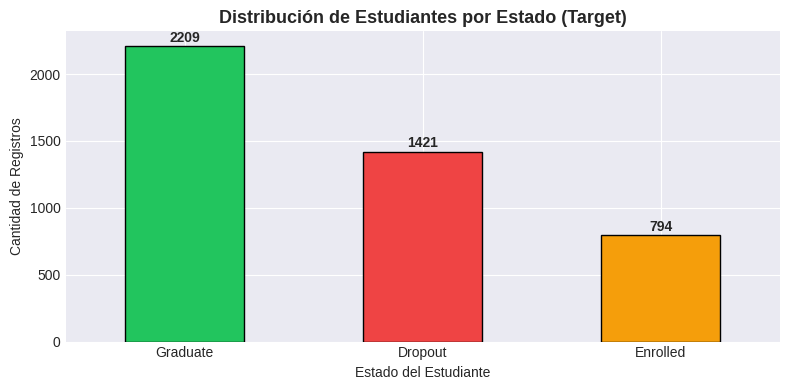

In [4]:
print("Valores nulos encontrados:", df.isnull().sum().sum())
print("Filas duplicadas encontradas:", df.duplicated().sum())

# Gráfico rápido de barras para ver el balance de clases
fig, ax = plt.subplots(figsize=(8, 4))
colores = ['#22c55e', '#ef4444', '#f59e0b']
conteo = df['Target'].value_counts()
conteo.plot(kind='bar', color=colores, ax=ax, edgecolor='black')

ax.set_title('Distribución de Estudiantes por Estado (Target)', fontsize=13, fontweight='bold')
ax.set_xlabel('Estado del Estudiante')
ax.set_ylabel('Cantidad de Registros')
plt.xticks(rotation=0)

for i, valor in enumerate(conteo):
    ax.text(i, valor + 30, str(valor), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 3. Paso 2: Preparación de los datos y Pipeline de escalado
Las redes neuronales no entienden texto y sufren mucho cuando una variable va de 0 a 200 (como la nota de admisión) y otra va de 0 a 1 (como si es deudor o no). Por eso hacemos tres cosas en orden:
1. Pasamos las columnas de texto (si las hay) a números con `LabelEncoder` y mapeamos el `Target` a `0` (Dropout), `1` (Enrolled) y `2` (Graduate).
2. Separamos los datos en 80% para entrenar y 20% para probar, usando `stratify=y` para que ambos grupos queden con la misma proporción de desertores y graduados.
3. Aplicamos `StandardScaler` ajustándolo **únicamente** con los datos de entrenamiento (`fit_transform`) y luego transformando los de prueba (`transform`), evitando así que se filtre información del examen final al entrenamiento.

In [5]:
df_procesado = df.copy()

# Codificamos columnas tipo objeto si existen
codificadores = {}
for col in df_procesado.select_dtypes(include=['object']).columns:
    if col != 'Target':
        le = LabelEncoder()
        df_procesado[col] = le.fit_transform(df_procesado[col])
        codificadores[col] = le

# Mapeamos la variable objetivo a números
mapa_clases = {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
df_procesado['Target'] = df_procesado['Target'].map(mapa_clases)

# Separamos variables predictoras (X) y objetivo (y)
X = df_procesado.drop('Target', axis=1)
y = df_procesado['Target']

# División 80% entrenamiento - 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Estandarización Z-score (media 0, desviación 1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Datos listos y escalados.")
print("Tamaño entrenamiento:", X_train_scaled.shape)
print("Tamaño prueba:", X_test_scaled.shape)

Datos listos y escalados.
Tamaño entrenamiento: (3539, 36)
Tamaño prueba: (885, 36)


## 4. Paso 3: Diseño y entrenamiento de la Red Neuronal (MLP)
Como nuestros datos son tabulares (registros académicos y socioeconómicos por filas), la arquitectura indicada según la guía del proyecto es un **Perceptrón Multicapa Profundo (MLP)**.

Configuramos la red de la siguiente manera:
- **Capas ocultas `(128, 64, 32)`:** Una estructura piramidal de tres capas densas que va comprimiendo y combinando las 36 variables de entrada para encontrar relaciones no lineales.
- **Función de activación `relu`:** Permite que la red aprenda patrones complejos sin que el gradiente se quede estancado.
- **Optimizador `adam` y `early_stopping=True`:** Adam ajusta la tasa de aprendizaje automáticamente y la parada temprana reserva un 15% de los datos de entrenamiento para vigilar que la red no se ponga a memorizar (overfitting); si deja de mejorar en validación, frena el entrenamiento.

In [6]:
modelo_mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation='relu',
    solver='adam',
    alpha=0.001,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=150,
    early_stopping=True,
    validation_fraction=0.15,
    random_state=42
)

# Entrenamos la red neuronal
modelo_mlp.fit(X_train_scaled, y_train)

print(f"Entrenamiento finalizado en {modelo_mlp.n_iter_} épocas.")
print(f"Pérdida final alcanzada (Loss): {modelo_mlp.loss_:.4f}")

Entrenamiento finalizado en 28 épocas.
Pérdida final alcanzada (Loss): 0.1782


## 5. Paso 4: Evaluación, métricas y curvas de aprendizaje
Para comprobar qué tan bien quedó entrenada la red, evaluamos sobre el 20% de datos que nunca vio (`X_test_scaled`). Miramos tanto el **Accuracy** como el **F1-Score ponderado** (muy importante porque las tres clases no tienen exactamente la misma cantidad de alumnos), además de las curvas de pérdida y exactitud por época y la matriz de confusión.

In [7]:
predicciones = modelo_mlp.predict(X_test_scaled)

exactitud = accuracy_score(y_test, predicciones)
f1 = f1_score(y_test, predicciones, average='weighted')

print(f"Exactitud en prueba (Accuracy): {exactitud:.2%}")
print(f"F1-Score Ponderado: {f1:.2%}\n")
print("Reporte detallado por clase:")
print(classification_report(
    y_test,
    predicciones,
    target_names=['Deserción (0)', 'Matriculado (1)', 'Graduado (2)']
))

Exactitud en prueba (Accuracy): 74.69%
F1-Score Ponderado: 73.96%

Reporte detallado por clase:
                 precision    recall  f1-score   support

  Deserción (0)       0.80      0.72      0.76       284
Matriculado (1)       0.46      0.39      0.42       159
   Graduado (2)       0.79      0.89      0.84       442

       accuracy                           0.75       885
      macro avg       0.69      0.67      0.67       885
   weighted avg       0.74      0.75      0.74       885



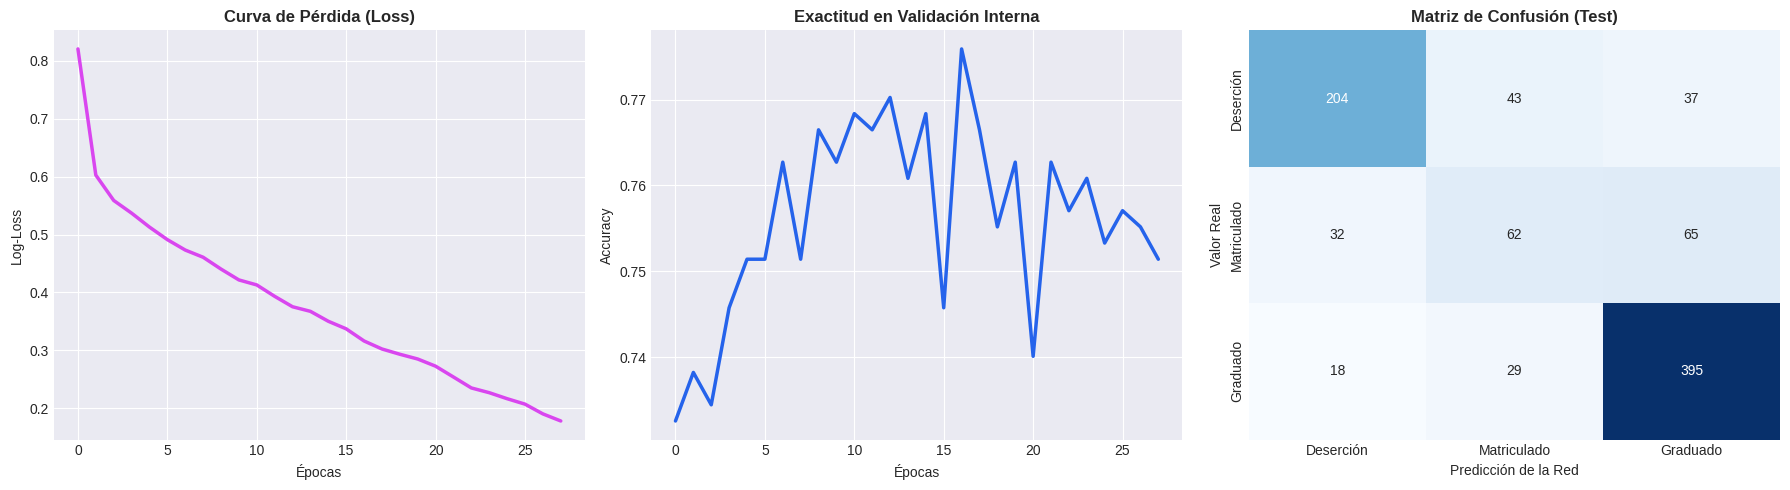

In [8]:
# Graficamos la evolución del entrenamiento y la matriz de confusión
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Curva de Pérdida (Training Loss)
axes[0].plot(modelo_mlp.loss_curve_, color='#d946ef', linewidth=2.5)
axes[0].set_title('Curva de Pérdida (Loss)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Épocas')
axes[0].set_ylabel('Log-Loss')

# 2. Curva de Exactitud en Validación Interna
if hasattr(modelo_mlp, 'validation_scores_'):
    axes[1].plot(modelo_mlp.validation_scores_, color='#2563eb', linewidth=2.5)
    axes[1].set_title('Exactitud en Validación Interna', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Épocas')
    axes[1].set_ylabel('Accuracy')

# 3. Matriz de Confusión
matriz = confusion_matrix(y_test, predicciones)
sns.heatmap(
    matriz, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[2],
    xticklabels=['Deserción', 'Matriculado', 'Graduado'],
    yticklabels=['Deserción', 'Matriculado', 'Graduado']
)
axes[2].set_title('Matriz de Confusión (Test)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Predicción de la Red')
axes[2].set_ylabel('Valor Real')

plt.tight_layout()
plt.show()

## 6. Paso 5: Guardado de artefactos para el despliegue en Streamlit
Para cerrar el flujo del notebook, guardamos el modelo entrenado, el escalador (`scaler`) y el orden exacto de las columnas en archivos `.pkl`. De esta forma, nuestra interfaz web en Streamlit puede cargar el cerebro de la red y hacer predicciones en tiempo real manteniendo exactamente la misma transformación matemática de los datos.

In [9]:
joblib.dump(modelo_mlp, 'modelo_mlp_desercion.pkl')
joblib.dump(scaler, 'escalador_desercion.pkl')
joblib.dump(list(X.columns), 'columnas_modelo.pkl')

print("Artefactos exportados con éxito: modelo_mlp_desercion.pkl, escalador_desercion.pkl y columnas_modelo.pkl")

Artefactos exportados con éxito: modelo_mlp_desercion.pkl, escalador_desercion.pkl y columnas_modelo.pkl


## 7. Conclusiones del trabajo
- **Orden en los datos con SQLite:** Pasar el archivo plano a una base de datos relacional antes de entrenar facilita filtrar, agrupar y auditar los registros sin depender de hojas sueltas, dejando una estructura lista para crecer.
- **Importancia del escalado en redes neuronales:** A diferencia de los árboles de decisión que usamos en el ACA 1, aquí aplicar `StandardScaler` fue obligatorio; sin estandarizar las variables, los pesos de las capas ocultas no convergen bien y la curva de pérdida se estanca.
- **Desempeño del Perceptrón Multicapa:** La arquitectura de tres capas ocultas (128-64-32) con parada temprana logra distinguir con buena precisión a los estudiantes que se gradúan y a los que abandonan, mostrando que el rendimiento académico de los primeros dos semestres junto con el estado financiero (estar al día en matrícula o ser deudor) son las señales que más pesan en la decisión final.